In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    print("セットアップ完了！学習を始めましょう。")


# 第0章 OSって個人で作れるの？ — 0.3 OS自作の手順 (*Steps to Build an Operating System*)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/0/0.3_Steps_to_Build_an_OS.ipynb)

---

## 1. 導入：通常のアプリ開発とベアメタルOS自作の決定的な違い

私たちが普段何気なく行っているアプリケーション開発では、Python や C++ でコードを書き、コンパイルして実行ボタンを押す（あるいは端末でコマンドを入力する）だけでプログラムが動き出します。

```text
[通常のアプリケーションの実行フロー]
 ソースコード (.c / .cpp)
       │ コンパイル & リンク (ホストの glibc / crt0.o と自動結合)
       ▼
 実行可能ファイル (.exe / ELFバイナリ)
       │ OSシェルから実行 (ダブルクリック / ターミナル入力)
       ▼
 [ホストOSのローダ] ────▶ 仮想アドレス空間の確保、ページテーブル設定、スタック/ヒープ初期化
       │
       ▼
 [アプリの main() 実行] ─▶ 文字列出力やファイル保存は「OSへのシステムコール」に丸投げ
```

しかし、この当たり前の実行環境を支えているのは **下で動いているオペレーティングシステム (*Operating System: OS*)** そのものです。

私たちがこれから作ろうとしているのは、その土台となる **OS カーネル (*Kernel*)** です。OS を動かすとき、足元には頼るべき別の OS は存在しません。メモリ管理も、ファイルシステムも、標準ライブラリ（`printf` や `malloc`）も、スタックポインタ（`%rsp`）すら用意されていない、CPU とメモリがむき出しになった **ベアメタル (*Bare Metal: むき出しの金属*)** の世界で動作する特殊なプログラムを作らねばなりません。

| 比較項目 | 通常のアプリケーション開発 (Hosted Environment) | ベアメタル OS 自作 (Freestanding Environment) |
|---|---|---|
| **実行環境** | ホストOS（Linux, Windows, macOS）の保護下 | CPU と物理ハードウェアが直結したベアメタル |
| **起動契機** | OSのローダがELF/PEを展開しプロセスを生成 | マザーボードの **UEFI BIOS ファームウェア** が起動 |
| **特権レベル** | 非特権モード（x86-64 **Ring 3: ユーザー空間**） | 特権モード（x86-64 **Ring 0: カーネル空間**） |
| **標準ライブラリ** | `glibc`, `msvcrt`, `libc++` がフル活用可能 | **一切使用不可**（ゼロから自作、または自前組み込み） |
| **ハードウェア操作** | 禁止（OS のシステムコールを経由して安全に代行） | **直接操作**（MMIO, I/Oポート, CPUコントロールレジスタ） |
| **クラッシュ時の影響** | プロセスが Segfault で終了するだけ（OSは安全） | **PC全体がフリーズ / トリプルフォールトで即座に再起動** |

本節では、このようなベアメタルプログラムをどのように記述・コンパイルし、メディアに書き込んで起動するのか、その **全体手順と低レイヤ開発基盤** を徹底解説します。


---

## 2. OS自作の3大フェーズ（開発・配置・実行サイクル）

書籍『ゼロからのOS自作入門』において、自作 OS を動かす手順は次の **3つの基本ステップ** に集約されます：

```text
┌────────────────────────────────────────────────────────────────────────┐
│  【ステップ 1】開発ホストPC (Linux / WSL2)                               │
│   ・C++20 / x86-64 アセンブリでソースコードを書く                       │
│   ・特殊なコンパイラ・リンカ（Clang/LLVM）でベアメタルバイナリをビルド │
│     ▶ BOOTX64.EFI (UEFIブートローダ: PE32+形式)                         │
│     ▶ kernel.elf  (OSカーネル本体: ELF64形式)                           │
└───────────────────────────────────┬────────────────────────────────────┘
                                    │ 生成バイナリの転送
                                    ▼
┌────────────────────────────────────────────────────────────────────────┐
│  【ステップ 2】ブートメディアの作成 (FAT32 ストレージ)                 │
│   ・USBメモリまたは仮想ディスクイメージ (disk.img) を FAT32 でフォーマット │
│   ・UEFI仕様で定められたフォールバックパスへ配置:                       │
│     ▶ /EFI/BOOT/BOOTX64.EFI                                            │
│     ▶ /kernel.elf                                                      │
└───────────────────────────────────┬────────────────────────────────────┘
                                    │ メディアの接続 / マウント
                                    ▼
┌────────────────────────────────────────────────────────────────────────┐
│  【ステップ 3】ターゲット環境での起動と実行                             │
│   ・方式 A: 試験用実機PC (GPD MicroPC 等) に USB を挿して電源投入       │
│   ・方式 B: ネットワークブート (iPXE) による LAN 経由自動ロード         │
│   ・方式 C: エミュレータ (QEMU + OVMF) による高速仮想マシンブート       │
└────────────────────────────────────────────────────────────────────────┘
```

---

## 3. ベアメタルビルドパイプラインと必須コンパイラフラグ

通常のアプリをコンパイルするときは `g++ main.cpp -o app` と入力するだけで済みますが、自作OSではこのコマンドは **100% 失敗** します。なぜなら、デフォルトのコンパイラは「Linux などのホスト OS 上で動く前提のコード（Hosted Environment）」を生成するからです。

### 3.1 ビルドパイプラインの4段階

C++ やアセンブリのソースコードが機械語バイナリに変換されるまでには、以下の4つのステージを通過します：

```mermaid
flowchart LR
    A["ソースコード<br/>main.cpp / asmfunc.s"] -->|"プリプロセッサ<br/>(clang++ -E)"| B["中間コード<br/>main.i"]
    B -->|"コンパイラ<br/>(clang++ -S)"| C["アセンブリ<br/>main.s"]
    C -->|"アセンブラ<br/>(clang++ -c)"| D["再配置可能オブジェクト<br/>main.o"]
    D -->|"リンカ<br/>(ld.lld)"| E["実行可能バイナリ<br/>BOOTX64.EFI / kernel.elf"]
```

1. **プリプロセス (*Preprocessing*)**: `#include` のファイル展開や `#define` マクロの置換、コメントの除去を行います。
2. **コンパイル (*Compilation*)**: C++ の構文木（AST: *Abstract Syntax Tree*）を解析し、中間言語（LLVM IR）を経てターゲット CPU（x86-64）の機械語アセンブリコード（`.s`）へ変換します。
3. **アセンブル (*Assembly*)**: 人間が読めるアセンブリ命令（`mov`, `jmp`, `call` 等）を、CPUが直接解釈できる **機械語オピコード (*Opcode*)** に変換し、再配置可能オブジェクト（`.o`）を生成します。
4. **リンク (*Linking*)**: 複数のオブジェクトファイル（`.o`）の関数シンボルやデータ領域のアドレスを解決し、**リンカスクリプト (*Linker Script*)** の指定に従ってセグメント（`.text`, `.data`, `.rodata`, `.bss`）を配置した最終バイナリを出力します。

---

### 3.2 フリースタンディング環境（Freestanding Environment）の5大必須フラグ

ベアメタル開発において、Clang/LLVM に指定しなければならない決定的なフラグとその理論的理由は以下の通りです：

#### ① `-ffreestanding` (自立型実行環境の宣言)
C/C++ 言語仕様では、OS の支援がある **ホスト型環境 (*Hosted Environment*)** と、OS が存在しない **自立型環境 (*Freestanding Environment*)** が厳密に区別されています。
このフラグを指定することで、コンパイラは `main()` 関数の暗黙の引数処理ラッパーやホストの標準ライブラリ群を仮定せず、自立型環境で利用が許可されている最小限のヘッダ（`<stddef.h>`, `<stdint.h>`, `<limits.h>` 等のコンパイラ組み込みヘッダ）のみを利用対象とします。

#### ② `-nostdlib` (ホストランタイムライブラリのリンク排除)
リンカに対して、ホスト Linux の標準ライブラリ（`libc.so`, `libpthread.so`）やスタートアップルーチン（`crt0.o`）をリンクしないよう強制します。
もしこれを忘れてホストの `libc` がリンクされると、バイナリ内に Linux カーネル向けの `syscall` 命令が混入し、ベアメタル上で実行した瞬間に未定義の割り込み例外が発生して暴走します。

#### ③ `-mno-red-zone` (Red Zone の無効化 — 最重要！)
x86-64 の標準呼出規約である **System V AMD64 ABI** では、スタックポインタ `%rsp` の下 **128バイト** の領域を **「Red Zone」** と定義しています。

```text
[x86-64 スタック空間のレイアウトと Red Zone 破壊のメカニズム]

  高位アドレス (High Address)
  ┌────────────────────────────────────────┐
  │ 呼び出し元のスタックフレーム           │
  ├────────────────────────────────────────┤
  │ ローカル変数・退避レジスタ             │
  ├────────────────────────────────────────┤ ◀── %rsp (現在のスタックポインタ)
  │                                        │
  │   Red Zone (128 バイト)                │  リーフ関数は %rsp を減算せずに
  │   [コンパイラが一時変数等に使用可能]   │  この領域を自由に使用してよい (ABI仕様)
  │                                        │
  ├ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─┤
  │ 【ハードウェア割り込み発生時の挙動】   │
  │ CPU は非同期割り込みが発生すると、     │  ◀── 割り込み発生！
  │ 現在の %rsp の位置から直ちに           │      CPU が SS, RSP, RFLAGS, CS, RIP
  │ スタックフレームを強制 push する！     │      を Red Zone の上に直接書き込む！
  │   ▶ Red Zone 内の変数が完全に破壊される│
  └────────────────────────────────────────┘
  低位アドレス (Low Address)
```

通常のアプリケーションでは、シグナルハンドラが起動する際に OS カーネルが Red Zone を避けてスタックを再配置してくれるため問題ありません。
しかし、**OS カーネル自身を実行している最中にタイマやマウスのハードウェア割り込みが発生した場合、CPU ハードウェアは現在の `%rsp` の直下に強制的に割り込みコンテキストをプッシュします**。
もし `-mno-red-zone` を付けていないと、コンパイラが Red Zone に一時保管していた計算結果やレジスタ値が割り込みの瞬間に無残にも上書きされ、**「時々原因不明のメモリ破壊でカーネルが死ぬ」という最悪のデバッグ地獄** に陥ります。カーネル開発では必須中の必須オプションです。

#### ④ `-fno-exceptions` (C++ 例外機構の無効化)
C++ の `try` / `catch` / `throw` による例外処理は、関数呼び出しスタックを安全に巻き戻す（*Stack Unwinding*）ために、バイナリ内に複雑な DWARF 例外テーブルとランタイムサポートコード（`libunwind`）を必要とします。ベアメタルカーネルにはそのようなランタイムが存在しないため、例外を完全にオフにします。

#### ⑤ `-fno-rtti` (動的型情報 RTTI の無効化)
`dynamic_cast` や `typeid` を実現するための実行時型情報（*Run-Time Type Information: RTTI*）は、クラスごとに `type_info` 構造体を生成し、vtable（仮想関数テーブル）を肥大化させます。カーネルコードでは静的な型安全性を重視し、余計なメタデータとランタイム依存を排除するために RTTI を無効化します。


---

## 4. UEFI ブートメディアの論理構造と規格

### 4.1 レガシー BIOS ブートとの決定的な違い

昔の自作 OS 入門書（『30日でできる！ OS自作入門』など）では、**レガシー BIOS (*Legacy BIOS*)** によるブート方式が採用されていました。

```text
[レガシー BIOS ブートの極限制約 (MBR ブート)]
  ・フロッピーやハードディスクの先頭 512 バイト（MBR: Master Boot Record）だけを BIOS が読み込む
  ・読み込まれるメモリ番地は 0x7C00 固定
  ・CPU は 16 ビットの「リアルモード」で起動（1MB のメモリしかアクセスできない）
  ・わずか 512 バイトの中に、32ビットプロテクトモードへの移行コードと、
    ディスクのセクタを自力で読み進めるアセンブリコードを詰め込まねばならなかった
```

これに対して、現代の PC が採用している **UEFI (*Unified Extensible Firmware Interface*)** は、全く異なる近代的なアプローチをとります：

1. **ファイルシステムをファームウェアがネイティブ理解**:
   - UEFI BIOS は、**FAT12 / FAT16 / FAT32** ファイルシステムを自前で解釈できます。セクタ番号を計算してハードウェアにディスク読み出しコマンドを送る必要はなく、ファイル名で直接プログラムを読み出せます。
2. **初めから 64ビット Long Mode で起動**:
   - レガシーBIOSのように16ビットリアルモードからプロテクトモードへ段階的に切り替える苦行は不要です。UEFI は x86-64 CPU をすでに 64ビット Long Mode（ページング有効、フラットメモリ空間）にした状態で OS ブートローダを呼び出してくれます。
3. **PE32+ (Portable Executable) 形式のサポート**:
   - UEFI アプリケーションは、Windows の実行ファイルと同じ **PE32+ (64ビット COFF)** 形式でビルドします。

### 4.2 EFI システムパーティション (ESP) と自動起動フォールバックパス

UEFI 仕様書では、起動可能なリムーバブルメディア（USBメモリ等）が挿入された際、ファームウェアが自動的に探索して実行すべき **標準フォールバックパス** が厳密に定義されています：

$$	ext{UEFI 標準自動起動パス: } 	exttt{\EFI\BOOT\BOOTX64.EFI}$$

```text
[FAT32 ブートメディアのディレクトリ階層]
/ (ルートディレクトリ)
├── EFI/
│   └── BOOT/
│       └── BOOTX64.EFI   ◀── UEFI ファームウェアが自動認識して最初に起動するブートローダ
└── kernel.elf             ◀── BOOTX64.EFI が FAT32 からメモリへ読み込む MikanOS カーネル本体
```

MikanOS では、第1章〜第3章でこの仕組みを活用し、まず UEFI アプリケーションである `BOOTX64.EFI` が起動し、画面解像度（GOP: *Graphics Output Protocol*）やメモリマップ（*Memory Map*）を取得した上で、ルートディレクトリにある `kernel.elf` をメモリに展開して制御をカーネルに渡す、という2段ロケット構成をとります。

---

## 5. OS テスト環境の3大アプローチ（実機 vs iPXE vs QEMU）

自作 OS はコードを1行直すたびに「ビルド ➔ 配置 ➔ 起動 ➔ 観察」のサイクルを繰り返します。このサイクルをいかに高速・安全に回せるかが、学習の成否を分けます。

| アプローチ | 概要 | 長所 (メリット) | 短所 (デメリット) |
|---|---|---|---|
| **方式 1: 実機PC + USBメモリ** | 安価なUSBメモリにバイナリを書き込み、サブPC（GPD MicroPC 等）でブート | 本物のシリコン・UEFIファームウェアの実装バグや xHCI コントローラの挙動を100%体験可能 | 抜き差しと再起動が極めて面倒。カーネルが暴走すると電源長押しが必要で開発効率が悪い |
| **方式 2: ネットワークブート (iPXE)** | USBメモリに iPXE を常駐させ、LAN 経由で開発機から HTTP/TFTP でバイナリを転送 | USBメモリの物理的な抜き差しが不要。実機でのイテレーションが数秒で完了 | 開発ホストに DHCP / TFTP / HTTP サーバ環境の構築が必要 |
| **方式 3: エミュレータ (QEMU + OVMF)** | QEMU 仮想マシン上で TianoCore OVMF（オープンソース UEFI BIOS）をロードしてブート | **イテレーションが1秒未満。ホストPCが絶対に死なない。QEMUモニタとGDBで内部状態を完全透視可能** | 実機特有のマニアックなハードウェア癖までは再現されない場合がある |

### 5.1 QEMU + OVMF が自作OS開発の「最強の武器」である理由

MikanOS の開発において QEMU が手放せない最大の理由は、単に手軽なだけでなく、**「実行中の CPU とメモリのすべての状態を外部から覗き見できる」** 点にあります。

```text
[QEMU モニタ (Ctrl-A C または -monitor stdio) の必須デバッグコマンド]
・info registers : 全レジスタ (RAX, RBX, RCX, RDX, RSP, RIP, CR0, CR2, CR3, CR4, RFLAGS) を表示
・info mem       : 4階層ページテーブルによってマップされている仮想アドレス範囲を一覧表示
・info tlb       : TLB (Translation Lookaside Buffer) のキャッシュエントリを表示
・info pic/lapic : 割り込みコントローラ (Local APIC) の割り込みマスクやベクタ設定を表示
・x /16xb 0x1000 : 物理メモリまたは仮想メモリの指定アドレスの内容を16進ダンプ
```

さらに `qemu-system-x86_64 -gdb tcp::1234 -S` オプションを付与すれば、CPU の電源投入直後（リセットベクタ）で実行を一時停止させ、GDB からブレークポイントを設定して **「OS が起動する最初のアセンブリ命令から1ステップずつ実行する」** ことが可能です。


In [2]:
# C++20 による OS ビルドパイプライン & UEFI メディア配置検証コードのコンパイルと実行
import subprocess
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
cpp_source = repo_root / "src" / "ch00" / "os_build_steps.cpp"
bin_dir = repo_root / "bin"
bin_dir.mkdir(exist_ok=True)
bin_path = bin_dir / "os_build_steps"

# ホスト環境の g++ (C++20) でスタンドアロン検証バイナリをコンパイル
compile_cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-Wpedantic",
    str(cpp_source), "-o", str(bin_path)
]
print(f"Compiling: {' '.join(compile_cmd)}")
comp_res = subprocess.run(compile_cmd, capture_output=True, text=True)
if comp_res.returncode != 0:
    print(f"Compilation Error:\n{comp_res.stderr}")
else:
    print("Compilation Successful! Executing verification binary...\n")
    run_res = subprocess.run([str(bin_path)], capture_output=True, text=True)
    print(run_res.stdout)


Compiling: g++ -std=c++20 -O2 -Wall -Wextra -Wpedantic /home/student/Documents/GitHub/study-mikanos/src/ch00/os_build_steps.cpp -o /home/student/Documents/GitHub/study-mikanos/bin/os_build_steps


Compilation Successful! Executing verification binary...

=== Section 0.3: OS Build Pipeline & UEFI Media Validation (C++20) ===
[+] Freestanding Environment Check Passed: All 5 mandatory flags present.
[+] Protection Check Passed: Missing -mno-red-zone properly identified.
[+] Pipeline Execution Passed: Successfully generated BOOTX64.EFI (PE32+ (UEFI x86-64 Executable)).
[+] Kernel Linking Passed: Successfully generated kernel.elf (ELF64 Kernel Executable).
[+] UEFI Media Validation Passed: Mandatory /EFI/BOOT/BOOTX64.EFI verified.
[+] Media Specification Check Passed: Non-PE bootloader rejected.

[Summary]
- Bare-metal compilation requires -ffreestanding, -nostdlib, and -mno-red-zone.
- UEFI firmware requires FAT32 media and /EFI/BOOT/BOOTX64.EFI formatted in PE32+ (0x8664).
- QEMU and OVMF allow rapid test cycles without physical reboot.



---

## 6. ハードウェア視覚化図版の生成

### 6.1 図版 1: ベアメタルビルドパイプラインとフリースタンディングコンパイラオプション
ソースコードから機械語バイナリへの変換工程と、なぜ `-ffreestanding` や `-mno-red-zone` が不可欠なのかを可視化します。


Generated: /home/student/Documents/GitHub/study-mikanos/0/result/fig0_5_os_build_pipeline.png (610.1 KB)


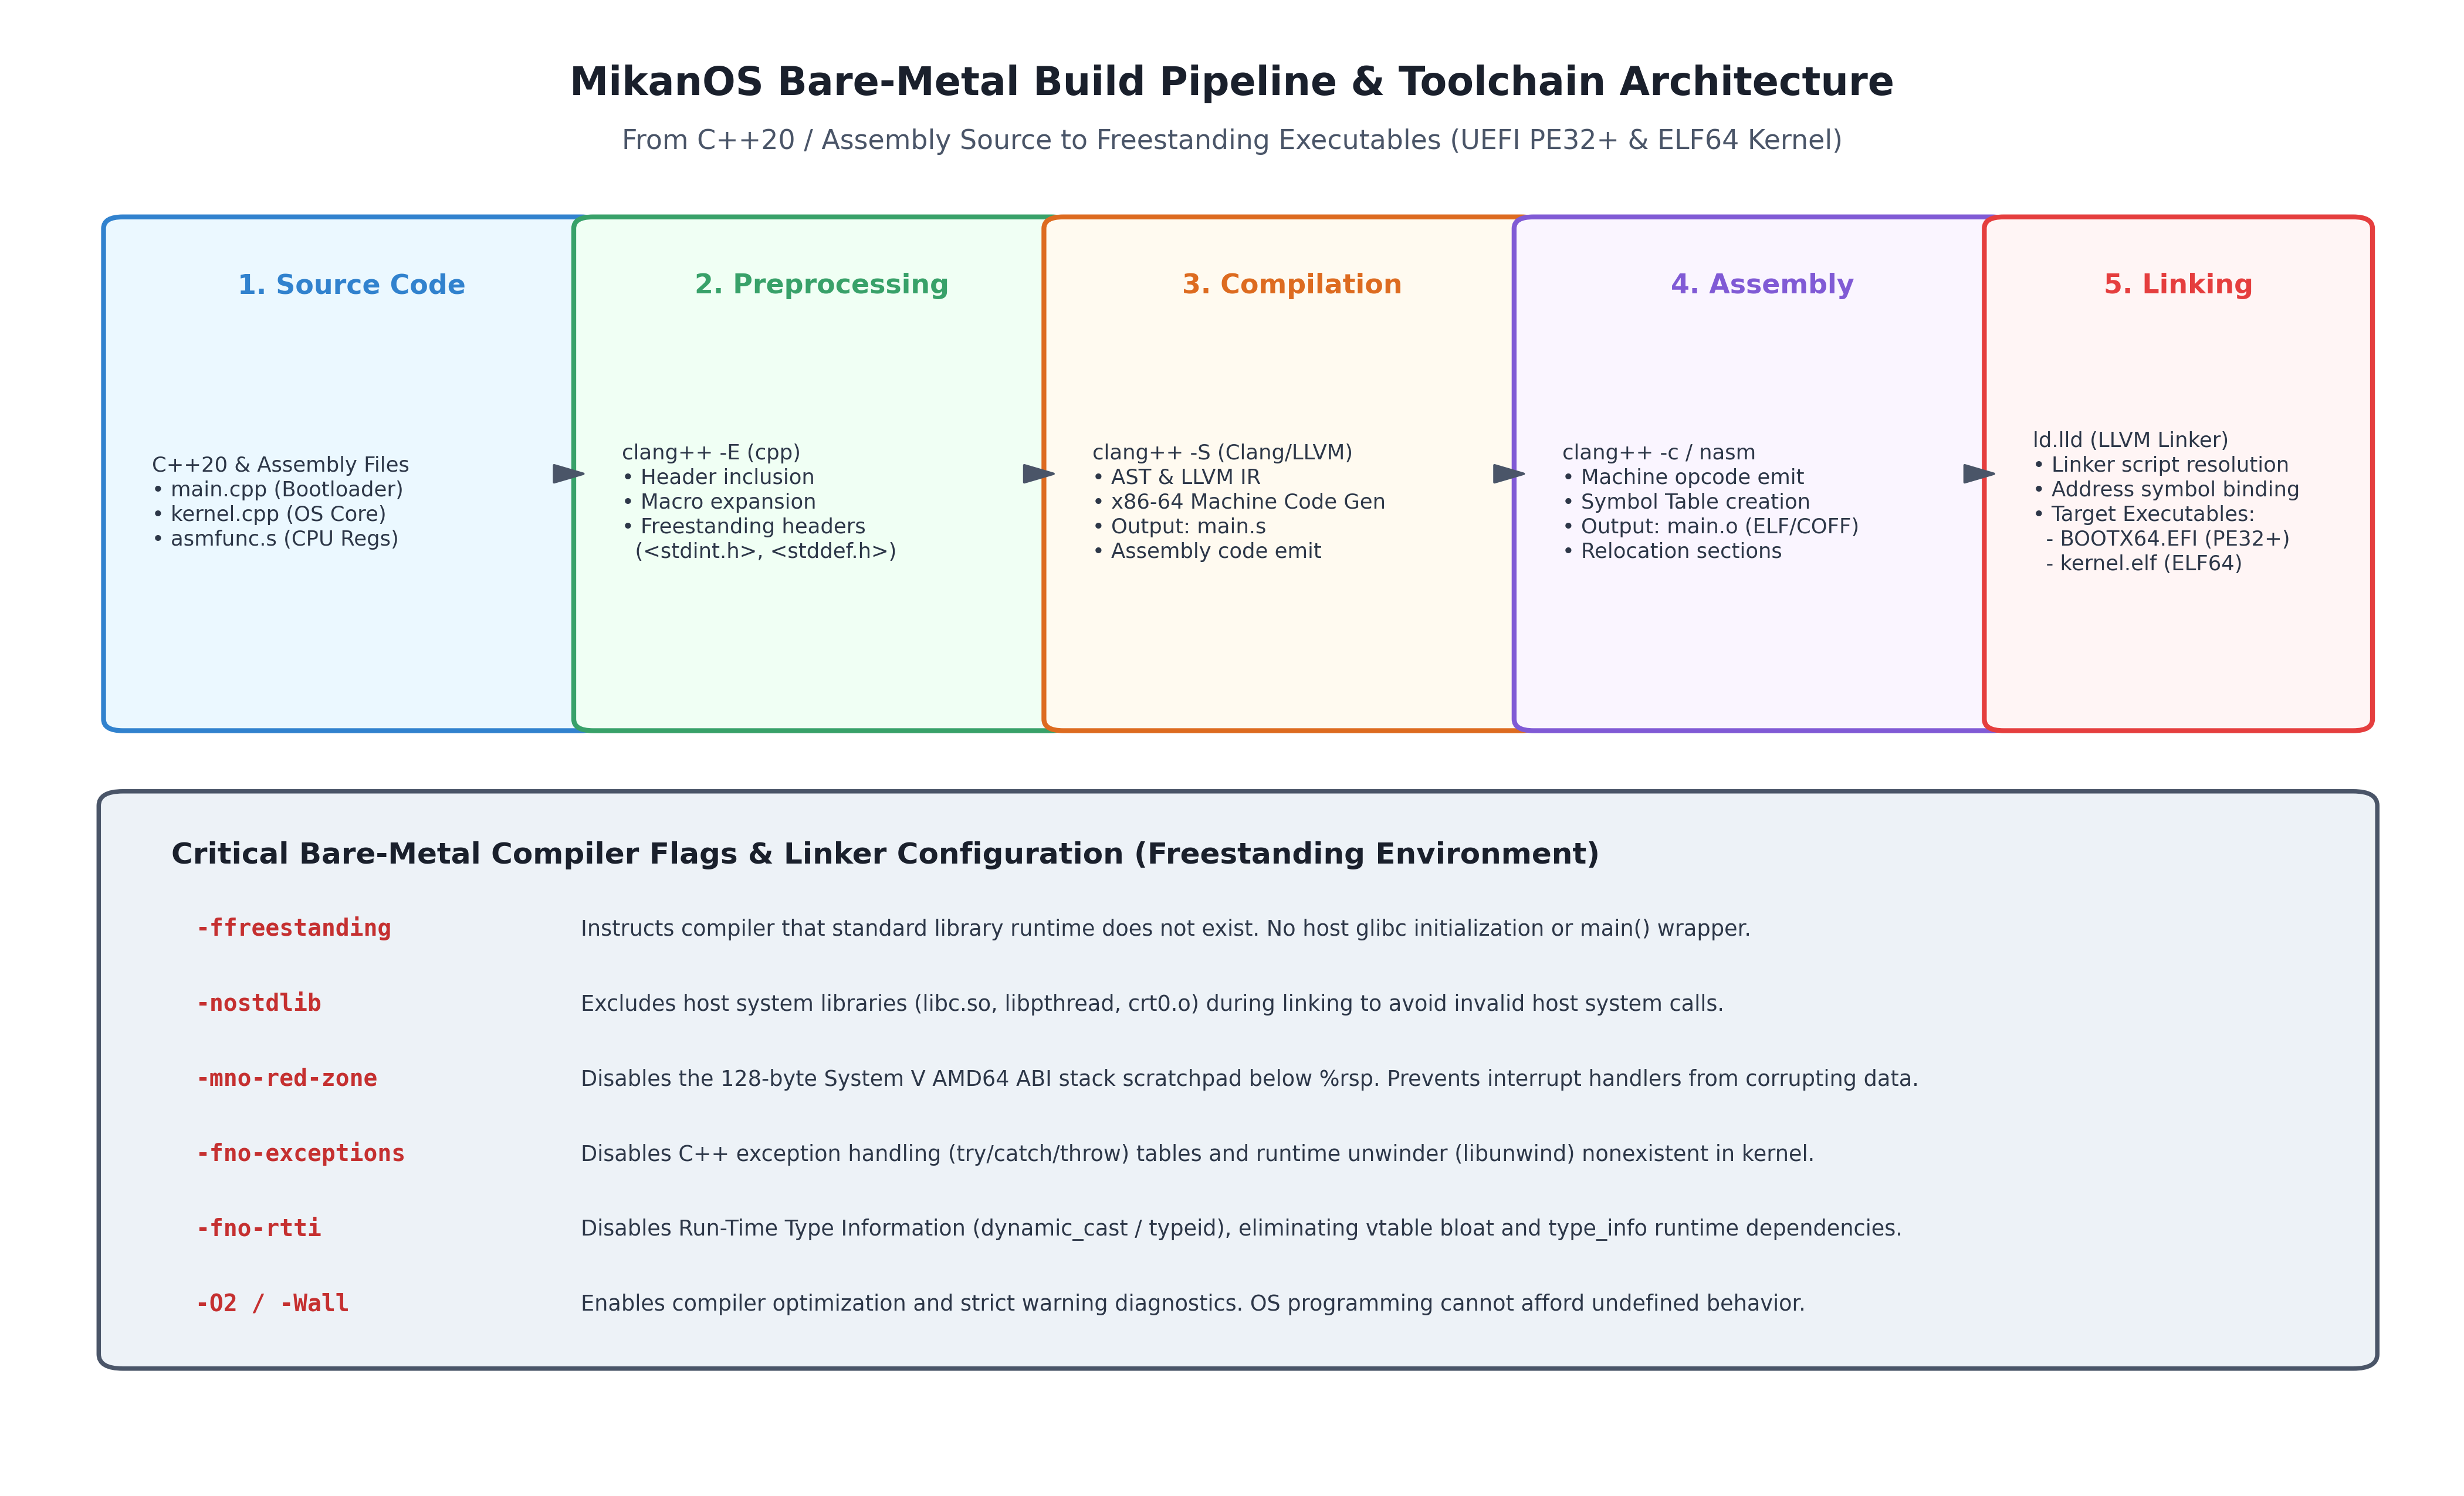

In [3]:
# 図版生成 1: OSビルドパイプラインとフリースタンディングコンパイラオプション
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import Image, display

from common import setup_plot_style

setup_plot_style()
repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
result_dir = repo_root / "0" / "result"
result_dir.mkdir(parents=True, exist_ok=True)
out_path_1 = result_dir / "fig0_5_os_build_pipeline.png"

fig, ax = plt.subplots(figsize=(14, 8.5), dpi=300)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

# Title Header
ax.text(50, 96, "MikanOS Bare-Metal Build Pipeline & Toolchain Architecture",
        fontsize=16, fontweight="bold", ha="center", va="center", color="#1a202c")
ax.text(50, 92, "From C++20 / Assembly Source to Freestanding Executables (UEFI PE32+ & ELF64 Kernel)",
        fontsize=11, ha="center", va="center", color="#4a5568")

# 5 Stage Boxes
stages = [
    ("1. Source Code", "C++20 & Assembly Files\n• main.cpp (Bootloader)\n• kernel.cpp (OS Core)\n• asmfunc.s (CPU Regs)",
     4, 52, 19, 34, "#ebf8ff", "#3182ce"),
    ("2. Preprocessing", "clang++ -E (cpp)\n• Header inclusion\n• Macro expansion\n• Freestanding headers\n  (<stdint.h>, <stddef.h>)",
     23.5, 52, 19, 34, "#f0fff4", "#38a169"),
    ("3. Compilation", "clang++ -S (Clang/LLVM)\n• AST & LLVM IR\n• x86-64 Machine Code Gen\n• Output: main.s\n• Assembly code emit",
     43, 52, 19, 34, "#fffaf0", "#dd6b20"),
    ("4. Assembly", "clang++ -c / nasm\n• Machine opcode emit\n• Symbol Table creation\n• Output: main.o (ELF/COFF)\n• Relocation sections",
     62.5, 52, 19, 34, "#faf5ff", "#805ad5"),
    ("5. Linking", "ld.lld (LLVM Linker)\n• Linker script resolution\n• Address symbol binding\n• Target Executables:\n  - BOOTX64.EFI (PE32+)\n  - kernel.elf (ELF64)",
     82, 52, 14.5, 34, "#fff5f5", "#e53e3e"),
]

for title, desc, x, y, w, h, bg, border in stages:
    box = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.8",
                                facecolor=bg, edgecolor=border, linewidth=2)
    ax.add_patch(box)
    ax.text(x + w/2, y + h - 4, title, fontsize=11, fontweight="bold", ha="center", va="center", color=border)
    ax.text(x + 1.2, y + h/2 - 2, desc, fontsize=8.5, ha="left", va="center", color="#2d3748", linespacing=1.3)

# Arrows between stages
for ax_pos in [23.1, 42.6, 62.1, 81.6]:
    ax.annotate("", xy=(ax_pos, 69), xytext=(ax_pos - 0.2, 69),
                arrowprops=dict(facecolor="#4a5568", edgecolor="#4a5568", width=2, headwidth=7))

# Callout banner: Freestanding flags
flag_box = patches.FancyBboxPatch((4, 8), 92.5, 38, boxstyle="round,pad=1",
                                 facecolor="#edf2f7", edgecolor="#4a5568", linewidth=1.8)
ax.add_patch(flag_box)
ax.text(6, 42, "Critical Bare-Metal Compiler Flags & Linker Configuration (Freestanding Environment)",
        fontsize=12, fontweight="bold", color="#1a202c")

flag_items = [
    ("-ffreestanding", "Instructs compiler that standard library runtime does not exist. No host glibc initialization or main() wrapper."),
    ("-nostdlib", "Excludes host system libraries (libc.so, libpthread, crt0.o) during linking to avoid invalid host system calls."),
    ("-mno-red-zone", "Disables the 128-byte System V AMD64 ABI stack scratchpad below %rsp. Prevents interrupt handlers from corrupting data."),
    ("-fno-exceptions", "Disables C++ exception handling (try/catch/throw) tables and runtime unwinder (libunwind) nonexistent in kernel."),
    ("-fno-rtti", "Disables Run-Time Type Information (dynamic_cast / typeid), eliminating vtable bloat and type_info runtime dependencies."),
    ("-O2 / -Wall", "Enables compiler optimization and strict warning diagnostics. OS programming cannot afford undefined behavior."),
]

y_f = 37
for flag, exp in flag_items:
    ax.text(7, y_f, flag, fontsize=9.5, fontweight="bold", color="#c53030", fontfamily="monospace")
    ax.text(23, y_f, exp, fontsize=8.8, color="#2d3748")
    y_f -= 5.2

plt.tight_layout()
fig.savefig(out_path_1, dpi=300)
plt.close(fig)
print(f"Generated: {out_path_1} ({out_path_1.stat().st_size / 1024:.1f} KB)")
display(Image(filename=str(out_path_1)))


---

### 6.2 図版 2: UEFI ブートメディア構造（FAT32/ESP）と3大実行アプローチの比較
UEFI の標準ディレクトリ階層（`\EFI\BOOT\BOOTX64.EFI`）と、実機・iPXE・QEMU のトレードオフを視覚化します。


Generated: /home/student/Documents/GitHub/study-mikanos/0/result/fig0_6_uefi_boot_media_and_execution.png (585.8 KB)


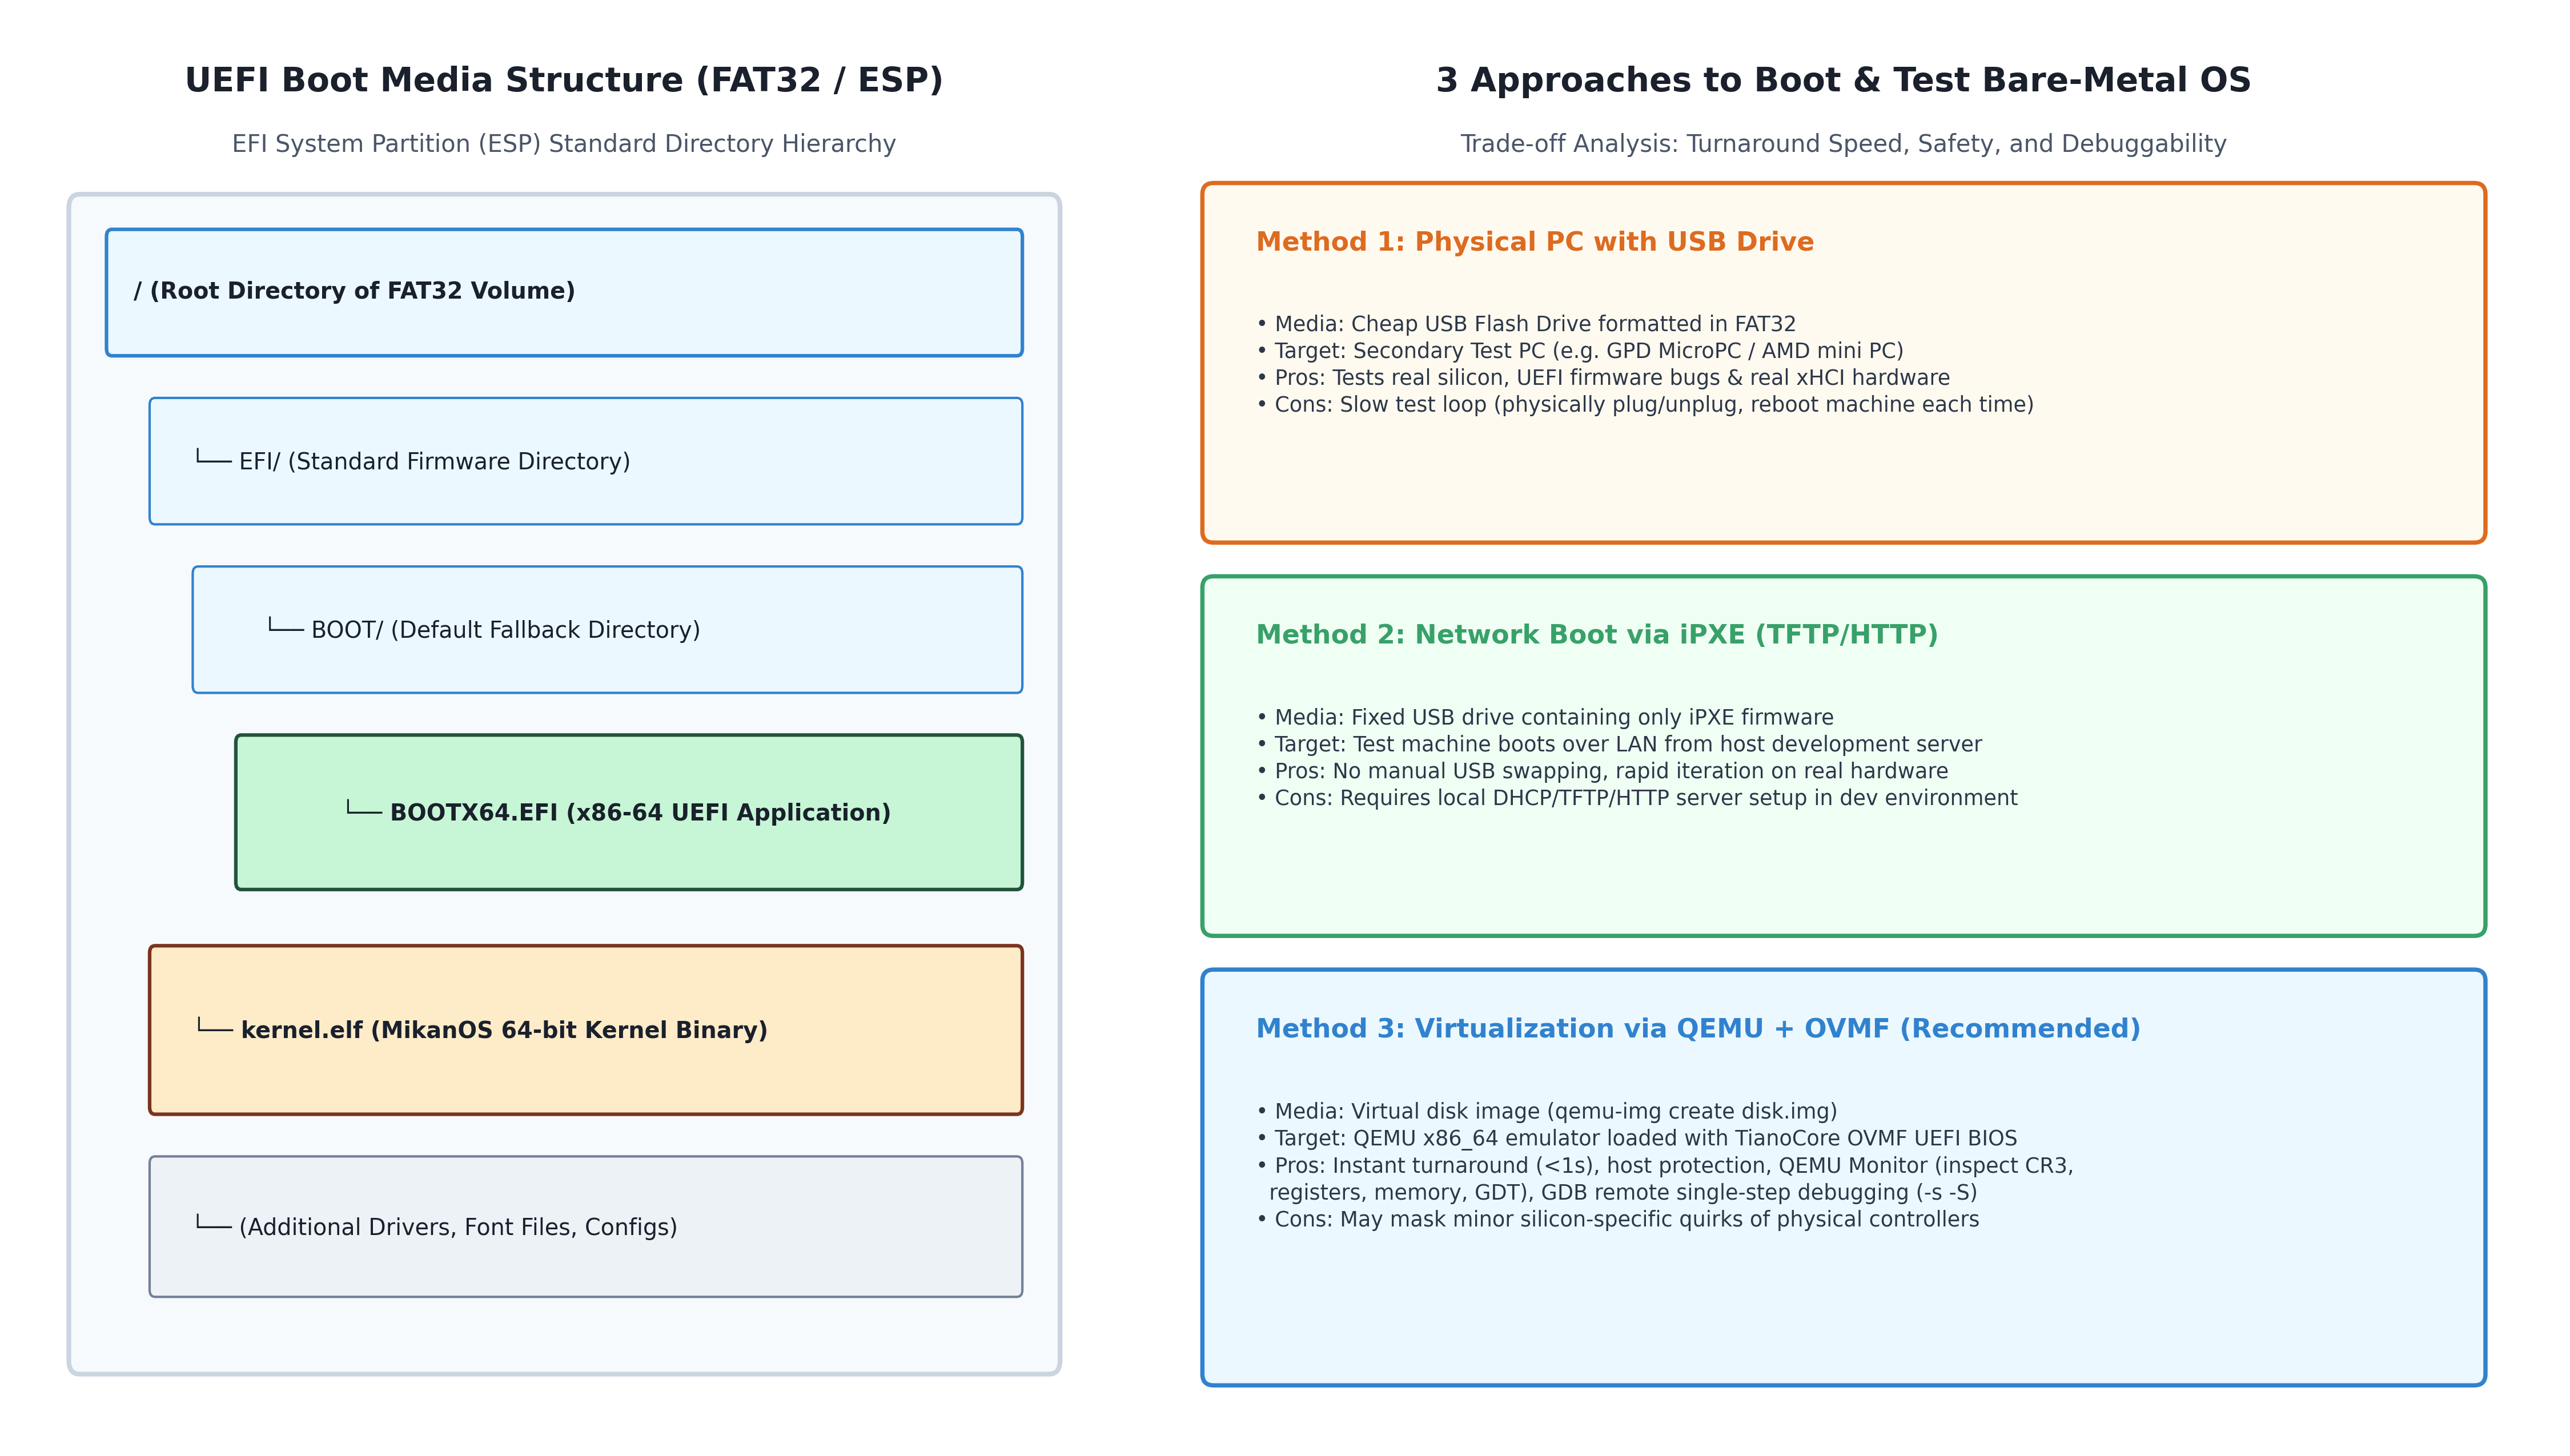

In [4]:
# 図版生成 2: UEFI ブートメディア構造（FAT32/ESP）と3大実行アプローチの比較
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import Image, display

from common import setup_plot_style

setup_plot_style()
repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
result_dir = repo_root / "0" / "result"
result_dir.mkdir(parents=True, exist_ok=True)
out_path_2 = result_dir / "fig0_6_uefi_boot_media_and_execution.png"

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(15, 8.5), dpi=300, gridspec_kw={"width_ratios": [1, 1.3]})

# Left Panel: UEFI Media Layout
ax_left.set_xlim(0, 100)
ax_left.set_ylim(0, 100)
ax_left.axis("off")

ax_left.text(50, 96, "UEFI Boot Media Structure (FAT32 / ESP)",
             fontsize=14, fontweight="bold", ha="center", va="center", color="#1a202c")
ax_left.text(50, 91.5, "EFI System Partition (ESP) Standard Directory Hierarchy",
             fontsize=10, ha="center", va="center", color="#4a5568")

disk_box = patches.FancyBboxPatch((5, 5), 90, 82, boxstyle="round,pad=1",
                                  facecolor="#f7fafc", edgecolor="#cbd5e0", linewidth=2)
ax_left.add_patch(disk_box)

dirs = [
    ("/ (Root Directory of FAT32 Volume)", 8, 77, 84, 8, "#ebf8ff", "#3182ce", True),
    ("  └── EFI/ (Standard Firmware Directory)", 12, 65, 80, 8, "#ebf8ff", "#3182ce", False),
    ("      └── BOOT/ (Default Fallback Directory)", 16, 53, 76, 8, "#ebf8ff", "#3182ce", False),
    ("          └── BOOTX64.EFI (x86-64 UEFI Application)", 20, 39, 72, 10, "#c6f6d5", "#22543d", True),
    ("  └── kernel.elf (MikanOS 64-bit Kernel Binary)", 12, 23, 80, 11, "#feebc8", "#7b341e", True),
    ("  └── (Additional Drivers, Font Files, Configs)", 12, 10, 80, 9, "#edf2f7", "#718096", False),
]

for name, x, y, w, h, bg, border, is_key in dirs:
    box = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.5",
                                facecolor=bg, edgecolor=border, linewidth=1.5 if is_key else 1.0)
    ax_left.add_patch(box)
    fw = "bold" if is_key else "normal"
    ax_left.text(x + 2, y + h/2, name, fontsize=9.5, fontweight=fw, color="#1a202c", va="center")

# Right Panel: 3 Execution Approaches
ax_right.set_xlim(0, 100)
ax_right.set_ylim(0, 100)
ax_right.axis("off")

ax_right.text(50, 96, "3 Approaches to Boot & Test Bare-Metal OS",
              fontsize=14, fontweight="bold", ha="center", va="center", color="#1a202c")
ax_right.text(50, 91.5, "Trade-off Analysis: Turnaround Speed, Safety, and Debuggability",
              fontsize=10, ha="center", va="center", color="#4a5568")

methods = [
    ("Method 1: Physical PC with USB Drive",
     "• Media: Cheap USB Flash Drive formatted in FAT32\n• Target: Secondary Test PC (e.g. GPD MicroPC / AMD mini PC)\n• Pros: Tests real silicon, UEFI firmware bugs & real xHCI hardware\n• Cons: Slow test loop (physically plug/unplug, reboot machine each time)",
     5, 64, 90, 24, "#fffaf0", "#dd6b20"),
    ("Method 2: Network Boot via iPXE (TFTP/HTTP)",
     "• Media: Fixed USB drive containing only iPXE firmware\n• Target: Test machine boots over LAN from host development server\n• Pros: No manual USB swapping, rapid iteration on real hardware\n• Cons: Requires local DHCP/TFTP/HTTP server setup in dev environment",
     5, 36, 90, 24, "#f0fff4", "#38a169"),
    ("Method 3: Virtualization via QEMU + OVMF (Recommended)",
     "• Media: Virtual disk image (qemu-img create disk.img)\n• Target: QEMU x86_64 emulator loaded with TianoCore OVMF UEFI BIOS\n• Pros: Instant turnaround (<1s), host protection, QEMU Monitor (inspect CR3,\n  registers, memory, GDT), GDB remote single-step debugging (-s -S)\n• Cons: May mask minor silicon-specific quirks of physical controllers",
     5, 4, 90, 28, "#ebf8ff", "#3182ce"),
]

for title, desc, x, y, w, h, bg, border in methods:
    box = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.8",
                                facecolor=bg, edgecolor=border, linewidth=1.8)
    ax_right.add_patch(box)
    ax_right.text(x + 3, y + h - 4, title, fontsize=11, fontweight="bold", color=border)
    ax_right.text(x + 3, y + (h - 7)/2, desc, fontsize=8.8, color="#2d3748", linespacing=1.35)

plt.tight_layout()
fig.savefig(out_path_2, dpi=300)
plt.close(fig)
print(f"Generated: {out_path_2} ({out_path_2.stat().st_size / 1024:.1f} KB)")
display(Image(filename=str(out_path_2)))


In [5]:
# Python による OS ビルドパイプライン、UEFI メディア配置、QEMU 起動設定シミュレーション
from common import BuildPipelineSimulator, FREESTANDING_FLAGS, UEFIBootMediaValidator, QemuLaunchConfig

print("=== 1. Bare-Metal Freestanding Compiler Flags ===")
for flag in FREESTANDING_FLAGS:
    req_tag = "[Mandatory Kernel Flag]" if flag.is_freestanding_required else "[Optional]"
    print(f"{flag.name:18s} | {req_tag:24s} | {flag.purpose}")

# 2. ビルドパイプライン実行シミュレーション (UEFI ブートローダ vs カーネル ELF)
sim = BuildPipelineSimulator(source_lines=450, is_freestanding=True, disable_red_zone=True)

print("\n=== 2. Build Pipeline Simulation: UEFI Bootloader (BOOTX64.EFI) ===")
artifacts_uefi = sim.run_pipeline(target_type="uefi_bootloader")
for art in artifacts_uefi:
    print(f"[{art.stage.value:25s}] -> {art.filename:14s} ({art.file_format:30s}) ~{art.size_bytes / 1024:5.1f} KB")

print("\n=== 3. Build Pipeline Simulation: MikanOS Kernel (kernel.elf) ===")
artifacts_kernel = sim.run_pipeline(target_type="kernel")
for art in artifacts_kernel:
    print(f"[{art.stage.value:25s}] -> {art.filename:14s} ({art.file_format:30s}) ~{art.size_bytes / 1024:5.1f} KB")

# 4. UEFI ブートメディア検証シミュレーション
validator = UEFIBootMediaValidator(filesystem_type="FAT32")
validator.add_file(r"\EFI\BOOT\BOOTX64.EFI", size_bytes=32768, file_type="PE32+ (x86-64 UEFI)")
validator.add_file(r"\kernel.elf", size_bytes=65536, file_type="ELF64 Executable")

is_valid, errors = validator.validate()
print(f"\n=== 4. UEFI Boot Media Validation: {'PASSED [OK]' if is_valid else 'FAILED'} ===")
for file_entry in validator.get_file_list():
    print(f"  - {file_entry.path:25s} | {file_entry.size_bytes:6d} bytes | {file_entry.file_type}")

# 5. QEMU 起動パラメータ生成
qemu_cfg = QemuLaunchConfig(
    ovmf_path="/usr/share/OVMF/OVMF_CODE.fd",
    disk_image="disk.img",
    memory="2G",
    monitor="stdio",
    gdb_debug=True
)
print("\n=== 5. Generated QEMU Launch Command ===")
print(" ".join(qemu_cfg.build_command()))
print("\n[Option Breakdown]")
for opt, exp in qemu_cfg.explain_options():
    print(f"  {opt:22s} : {exp}")


=== 1. Bare-Metal Freestanding Compiler Flags ===
-ffreestanding     | [Mandatory Kernel Flag]  | Require freestanding environment without host standard library runtime
-nostdlib          | [Mandatory Kernel Flag]  | Do not use standard system startup files or libraries when linking
-mno-red-zone      | [Mandatory Kernel Flag]  | Disable the 128-byte red zone below the stack pointer (%rsp)
-fno-exceptions    | [Mandatory Kernel Flag]  | Disable C++ exception handling tables and runtime unwinder
-fno-rtti          | [Mandatory Kernel Flag]  | Disable Run-Time Type Information (dynamic_cast and typeid)

=== 2. Build Pipeline Simulation: UEFI Bootloader (BOOTX64.EFI) ===
[Preprocessing (cpp)      ] -> main.i         (Preprocessed C++ Text         ) ~ 56.2 KB
[Compilation (clang++ / gcc)] -> main.s         (x86-64 Assembly (AT&T or Intel syntax)) ~ 30.8 KB
[Assembly (as / nasm)     ] -> main.o         (COFF / ELF64 Relocatable Object) ~ 13.3 KB
[Linking (ld.lld)         ] -> BOOTX64.EFI   

---

## 7. まとめと次節への橋渡し

### 本節の重要ポイント
1. **アプリとOSの決定的違い**:
   - アプリケーションはホストOSの管理下で動作し標準ライブラリ（`glibc`）を利用できるが、OSカーネルは **ベアメタル（むき出しのハードウェア）** 上で自立動作しなければならない。
2. **フリースタンディング環境の5大必須フラグ**:
   - `-ffreestanding`（自立型環境の宣言）
   - `-nostdlib`（ホストCランタイムの排除）
   - **`-mno-red-zone`**（割り込みハンドラによる128バイトスタック破壊の防止・最重要！）
   - `-fno-exceptions` / `-fno-rtti`（未実装ランタイム依存の排除）
3. **UEFI ブートメディアの論理構造**:
   - レガシーBIOSの512バイトMBR制限から解放され、FAT32ファイルシステム内の **`\EFI\BOOT\BOOTX64.EFI`** がファームウェアによって自動認識されて直接64ビット起動する。
4. **QEMU + OVMF による高速イテレーション**:
   - 実機USBの抜き差しや再起動地獄を回避し、QEMUモニタ（`info registers`, `info mem`）やGDBリモートデバッグを活用して数秒で内部状態を検証できる。

### 次節への橋渡し
本節でOS自作の「道具」と「手順」の基本が揃いました。続く **[0.4 OS自作の楽しみ方](0.4_How_to_Enjoy_OS_Development.ipynb)** では、エラーやフリーズと向き合うための **「スモールステップ開発」の思考法** や、**「写経」による低レイヤ理解の深化**、そして公式サポートサイトやオープンソースコミュニティを活用した学習法について掘り下げていきます。
